In [13]:
# Clustering: This fall under Unsupervise Machine Learning. 
# It involves classifying Data point into groups based on how close they are to the Centriod.

In [1]:
import pandas as pd 
import numpy as np 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_excel(r"C:\Users\Neptune\Documents\Documents\EARLYCODE\General Projects\walmart.xlsx")
df.head()

,Order ID,Order Date,Ship Date,Customer Name,Country,City,State,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,Darrin Van Huff,United States,Los Angeles,California,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [3]:
df.shape

(3203, 12)

In [4]:
# To pick the features we need to Clustering
features = df.iloc[:, [9, 10, 11]]
features

,Sales,Quantity,Profit
0,14.620,2,6.8714
1,48.860,7,14.1694
2,7.280,4,1.9656
3,907.152,4,90.7152
4,18.504,3,5.7825
...,...,...,...
3198,36.240,1,15.2208
3199,91.960,2,15.6332
3200,258.576,2,19.3932
3201,29.600,4,13.3200


In [12]:
print(f"{df["Sales"].max()} : {df["Sales"].min()}")
print(f"{df["Quantity"].max()} : {df["Quantity"].min()}")
print(f"{df["Profit"].max()} : {df["Profit"].min()}")

13999.96 : 0.99
14 : 1
6719.9808 : -3399.98


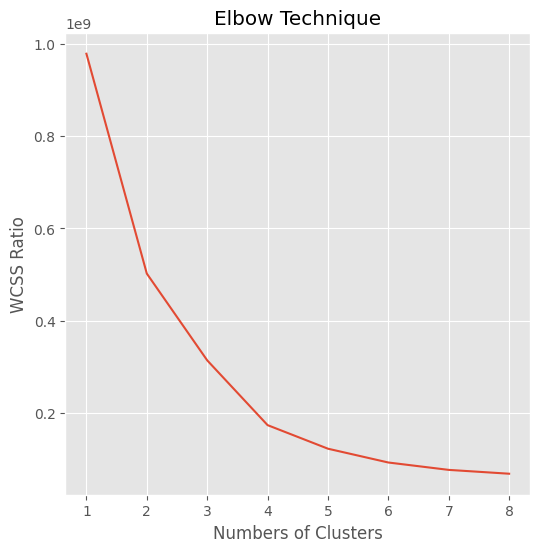

In [5]:
# To get WSS( Within cluster Sum of Squares)
wcss = []
for i in range(1, 9):
    kmeans = KMeans(n_clusters= i)
    kmeans.fit(features)
    wcss.append(kmeans.inertia_)
    
# To Plot the Diagram to identify the break which tells us the number of clusters
plt.style.use("ggplot")
plt.figure(figsize=(6, 6))
plt.plot(range(1, 9), wcss)
plt.title("Elbow Technique")
plt.ylabel("WCSS Ratio")
plt.xlabel("Numbers of Clusters")
plt.show()

In [6]:
# From the WCSS, We find out that we are going to classify our data into two different groups
model = KMeans(n_clusters= 2)
model.fit(features)
y_pred = model.predict(features)

In [7]:
# To add the Groups to the DataFrame.
df["Group"] = y_pred

In [8]:
# To see- all the Group that falls on Group Two.
df[df['Group'] == 1]

,Order ID,Order Date,Ship Date,Customer Name,Country,City,State,Category,Product Name,Sales,Quantity,Profit,Group
6,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Tables,Chromcraft Rectangular Conference Tables,1706.184,9,85.3092,1
13,CA-2012-106320,2012-09-25,2012-09-30,Emily Burns,United States,Orem,Utah,Tables,Bretford CR4500 Series Slim Rectangular Table,1044.630,3,240.2649,1
21,CA-2011-106376,2011-12-05,2011-12-10,Brendan Sweed,United States,Gilbert,Arizona,Art,Hunt BOSTON Model 1606 High-Volume Electric Pe...,1113.024,8,111.3024,1
72,CA-2013-145625,2013-09-12,2013-09-18,Kelly Collister,United States,San Diego,California,Accessories,LogitechÂ P710e Mobile Speakerphone,3347.370,13,636.0003,1
111,US-2011-135972,2011-09-21,2011-09-23,Jack Garza,United States,Des Moines,Washington,Copiers,Canon PC1080F Personal Copier,1799.970,3,701.9883,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,CA-2013-107104,2013-11-27,2013-12-01,Maribeth Schnelling,United States,Los Angeles,California,Bookcases,DMI Eclipse Executive Suite Bookcases,3406.664,8,160.3136,1
3091,CA-2013-160717,2013-06-07,2013-06-12,Maria Etezadi,United States,Santa Barbara,California,Phones,Samsung Galaxy Mega 6.3,3023.928,9,226.7946,1
3134,CA-2013-146913,2013-11-01,2013-11-06,Sylvia Foulston,United States,San Francisco,California,Chairs,Office Star - Professional Matrix Back Chair w...,1403.920,5,70.1960,1
3161,CA-2012-164301,2012-03-26,2012-03-30,Ellis Ballard,United States,Seattle,Washington,Tables,Bush Advantage Collection Racetrack Conference...,3393.680,8,610.8624,1


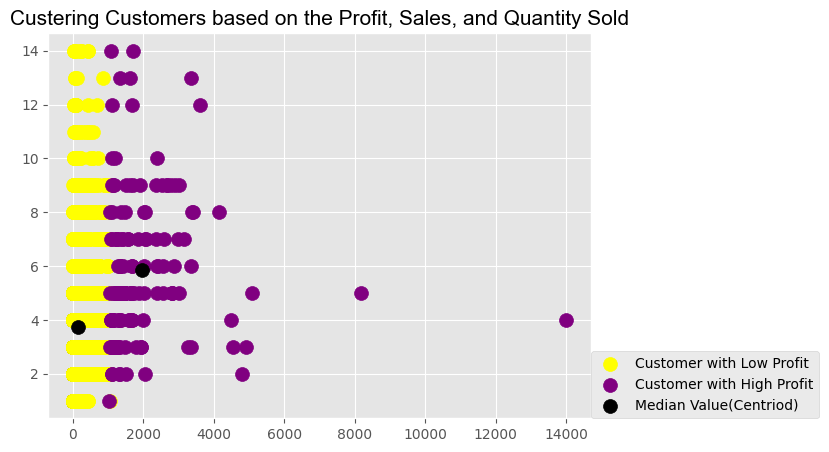

In [9]:
# To Visualize the Groups. 
x = features.to_numpy()
plt.style.use("ggplot")
plt.figure(figsize=(7, 5))
plt.scatter(x[y_pred == 0, 0], x[y_pred == 0,1], label = "Customer with Low Profit", c = "Yellow", s = 100)
plt.scatter(x[y_pred == 1, 0], x[y_pred == 1,1], label = "Customer with High Profit", c = "Purple", s = 100)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], s = 100, label = "Median Value(Centriod)", c = "Black")
plt.title("Custering Customers based on the Profit, Sales, and Quantity Sold", fontsize = 15, fontdict={"family":"Arial"})
plt.legend(loc = [1, 0])
plt.show()

In [13]:
import joblib as jb 
jb.dump(model, "customer_segementation.pki")

if jb: print("Model has been saved on your folder") 


Model has been saved on your folder
